# Lab 5 · Computer vision: semantic segmentation — Guided notebook

**BME · MSc Deep Learning / VITMMA19 · Fall 2026/2027**
Department of Telecommunications and Artificial Intelligence
**Instructor:** Dr. Mohammed Salah Al-Radhi

**30 minutes, including setup.** Then complete the 60-minute assignment, **02_BME_DL_Lab5_Assignment.ipynb**, independently.

In Lab 4 a network gave one label per image. Today's lecture moved to **semantic segmentation**: one label for **every pixel** (slide 65). This notebook builds the tools you need for that: per-pixel losses and metrics, the step from sliding windows to fully convolutional networks, down- and upsampling, BatchNorm's two modes, residual paths, augmentation that keeps image and labels consistent, and the idea of a self-supervised pretext task.

| Minutes | Activity |
| --- | --- |
| 0–4 | Setup and the digit scenes |
| 4–8 | Dense prediction: shapes and the per-pixel loss |
| 8–12 | Measuring segmentation: pixel accuracy, IoU, Dice |
| 12–17 | Sliding window, fully convolutional networks, down- and upsampling |
| 17–22 | BatchNorm in training and evaluation; residual paths |
| 22–26 | Augmentation for segmentation; a self-supervised pretext task |
| 26–30 | The experiment engine, a first baseline, and the assignment challenge |

Save a copy in Drive. **A CPU runtime is sufficient; a GPU is optional.** The digits ship with scikit-learn, so no download or account is needed.

## 1. Setup and the digit scenes · minutes 0–4

We reuse the scikit-learn digits and the **same split IDs as Labs 3–4**. Each 24×24 scene contains two digits, which often touch or partly cover each other (occlusion, slide 39); every pixel is labelled **0 = background** or **k + 1 = digit k** (11 classes). Training scenes come only from training digits, validation scenes only from validation digits, so no digit image appears on both sides of the split (slide 62: split *before* you generate or augment data).

Training images have *standard* conditions. Validation has two views of the same scenes: **standard** and **harsh** (strong light from one side, more pencil marks; slides 36 and 40: illumination and background clutter). The test scenes stay closed. The helper cells below are identical to those in the assignment.

In [1]:
import copy
import math
import os
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix as sk_confusion_matrix
from sklearn.model_selection import train_test_split

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(2, os.cpu_count() or 1))
SEED = 42
SPLIT_SEED = 2026                    # the same stratified digit IDs as Labs 3-4
CANVAS, NC = 24, 11                  # 24x24 scenes; 11 classes: 0 = background, k+1 = digit k
GLYPH_SIZES = (11, 14)               # each digit is drawn 11-14 px tall
EPOCHS, BATCH_SIZE, MAX_LR = 12, 32, 1e-2   # fixed budget: Adam with a one-cycle learning-rate schedule
N_TRAIN, N_VAL, N_TEST = 1200, 400, 400     # scenes, two digits each
STANDARD = dict(amp=(0.0, 0.3), offset=(0.0, 0.1), strokes=(0, 2), noise=0.05)   # training conditions
HARSH = dict(amp=(0.5, 0.9), offset=(0.15, 0.35), strokes=(3, 6), noise=0.05)    # deployment conditions
TASKS = ['T3', 'T4', 'T5', 'guided', 'extension']
RUNS, PREDICTIONS, TEST_OPENED = {}, {}, False
pd.set_option('display.precision', 3)
pd.set_option('display.width', 170)

print('Python:', platform.python_version(), '| PyTorch:', torch.__version__,
      '| scikit-learn:', sklearn.__version__)
print('Device:', DEVICE, '| CPU threads:', torch.get_num_threads())
print(f'Budget per run: {EPOCHS} epochs | batch {BATCH_SIZE} | Adam one-cycle, max lr {MAX_LR} | seed {SEED}')

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | scikit-learn: 1.9.1
Device: cpu | CPU threads: 2
Budget per run: 12 epochs | batch 32 | Adam one-cycle, max lr 0.01 | seed 42


In [2]:
#@title Provided data helpers — run this cell; expand to inspect
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_scenes(digits, pool, n, seed):
    """Clean 'ink' images and per-pixel labels. Two digits per scene, drawn only from the given pool of
    digit IDs, so training, validation and test scenes never share a digit image. Placement avoids overlap
    when there is room; on a 24x24 canvas the digits usually touch, and the second one often partly covers
    the first (occlusion): its strokes are drawn on top."""
    rng = np.random.default_rng(seed)
    ink = torch.zeros(n, 1, CANVAS, CANVAS)
    mask = torch.zeros(n, CANVAS, CANVAS, dtype=torch.long)
    for k in range(n):
        used = torch.zeros(CANVAS, CANVAS, dtype=torch.bool)
        for _ in range(2):
            i = pool[rng.integers(len(pool))]
            size = int(rng.integers(GLYPH_SIZES[0], GLYPH_SIZES[1] + 1))
            g = F.interpolate(torch.tensor(digits.images[i] / 16.0, dtype=torch.float32)[None, None],
                              size=(size, size), mode='bilinear', align_corners=False)[0, 0].clamp(0, 1)
            for _try in range(50):
                r, c = (int(v) for v in rng.integers(0, CANVAS - size + 1, 2))
                if not used[r:r + size, c:c + size].any():
                    break
            used[r:r + size, c:c + size] = True
            on = g > 0.35                                  # the annotation rule: stroke pixels
            ink[k, 0, r:r + size, c:c + size][on] = g[on]
            mask[k, r:r + size, c:c + size][on] = int(digits.target[i]) + 1
    return ink, mask

def make_stroke_bank(n=3000, seed=99):
    """Short random line segments used as background clutter. Clutter is labelled background."""
    rng = np.random.default_rng(seed)
    bank = torch.zeros(n, CANVAS, CANVAS)
    for k in range(n):
        r0, c0 = rng.uniform(0, CANVAS, 2)
        length, angle, value = rng.integers(4, 10), rng.uniform(0, math.pi), rng.uniform(0.3, 0.7)
        for t in range(length):
            rr, cc = int(round(r0 + t * math.sin(angle))), int(round(c0 + t * math.cos(angle)))
            if 0 <= rr < CANVAS and 0 <= cc < CANVAS:
                bank[k, rr, cc] = value
    return bank

STROKES = make_stroke_bank()
_YY, _XX = torch.meshgrid(torch.linspace(-1, 1, CANVAS), torch.linspace(-1, 1, CANVAS), indexing='ij')

def render(ink, gen, cond):
    """Photometric rendering of clean scenes: an illumination gradient in a random direction,
    a brightness offset, background clutter strokes and pixel noise. Labels never change:
    clutter is only drawn where there is no ink."""
    n = ink.shape[0]
    uniform = lambda lo, hi: lo + (hi - lo) * torch.rand(n, 1, 1, 1, generator=gen)
    theta = 2 * math.pi * torch.rand(n, 1, 1, 1, generator=gen)
    ramp = (torch.cos(theta) * _XX + torch.sin(theta) * _YY + 1) / 2        # 0 on one side, 1 on the other
    image = ink * (1 - uniform(*cond['amp']) * ramp) + uniform(*cond['offset']) * ramp
    lo, hi = cond['strokes']
    if hi > 0:
        count = torch.randint(lo, hi + 1, (n,), generator=gen)
        pick = torch.randint(0, len(STROKES), (n, hi), generator=gen)
        use = (torch.arange(hi)[None] < count[:, None]).float()[:, :, None, None]
        clutter = (STROKES[pick] * use).amax(1, keepdim=True)
        image = torch.where(ink < 0.05, torch.maximum(image, clutter), image)
    image = image + cond['noise'] * torch.randn(ink.shape, generator=gen)
    return image.clamp(0, 1)

def prepare_data():
    digits = load_digits()
    ids = np.arange(len(digits.target))
    dev_ids, test_ids = train_test_split(ids, test_size=0.2, stratify=digits.target, random_state=SPLIT_SEED)
    train_ids, val_ids = train_test_split(dev_ids, test_size=0.25, stratify=digits.target[dev_ids],
                                          random_state=SPLIT_SEED)
    assert set(train_ids).isdisjoint(val_ids) and set(train_ids).isdisjoint(test_ids)
    assert set(val_ids).isdisjoint(test_ids)
    tr_ink, tr_mask = make_scenes(digits, train_ids, N_TRAIN, seed=1)
    va_ink, va_mask = make_scenes(digits, val_ids, N_VAL, seed=2)
    tr_img = render(tr_ink, torch.Generator().manual_seed(11), STANDARD)
    data = dict(train_ink=tr_ink, train_img=tr_img, train_mask=tr_mask,
                val_ink=va_ink, val_mask=va_mask,
                val_standard=render(va_ink, torch.Generator().manual_seed(12), STANDARD),
                val_harsh=render(va_ink, torch.Generator().manual_seed(13), HARSH),
                mean=tr_img.mean().item(), std=tr_img.std().item())

    def final_test(run):
        """Teaching guard, not security: call once, after the decision is written down."""
        global TEST_OPENED
        if TEST_OPENED:
            raise RuntimeError('The test set was already opened. Reuse final_report; do not retune.')
        if run['task'] not in ('T3', 'T4', 'T5') or run['status'] != 'complete':
            raise ValueError('Choose a completed T3, T4 or T5 run.')
        TEST_OPENED = True
        te_ink, te_mask = make_scenes(digits, test_ids, N_TEST, seed=3)
        views = {'standard': render(te_ink, torch.Generator().manual_seed(14), STANDARD),
                 'harsh': render(te_ink, torch.Generator().manual_seed(15), HARSH)}
        report = {'run_name': run['name'], 'n_scenes': N_TEST}
        for view, x in views.items():
            pred = predict_masks(run['model'], x)
            report[view] = segmentation_scores(pred, te_mask)
            report[view + '_pred'] = pred
        report['images'], report['mask'] = views['harsh'], te_mask
        return report
    return data, final_test

MASK_COLOURS = ListedColormap(['#f2f2f2', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
                               '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf'])

def show_masks(rows, titles, n=6, suptitle=None):
    """rows: list of tensors, each (N, 1, H, W) images or (N, H, W) masks."""
    fig, axes = plt.subplots(len(rows), n, figsize=(1.7 * n, 1.75 * len(rows)), squeeze=False)
    for r, (data_row, title) in enumerate(zip(rows, titles)):
        for i in range(n):
            ax = axes[r, i]
            if data_row.dim() == 4:
                ax.imshow(data_row[i, 0], cmap='gray', vmin=0, vmax=1)
            else:
                ax.imshow(data_row[i], cmap=MASK_COLOURS, vmin=0, vmax=NC - 1, interpolation='nearest')
            ax.set_xticks([]); ax.set_yticks([])
        axes[r, 0].set_ylabel(title, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    fig.tight_layout()
    plt.show()

Scenes  train / validation / test: 1200 400 400 (test scenes are built only when opened)
Image tensor: (400, 1, 24, 24) | mask tensor: (400, 24, 24) torch.int64
Normalisation from standard training images only: mean 0.1578, std 0.2570


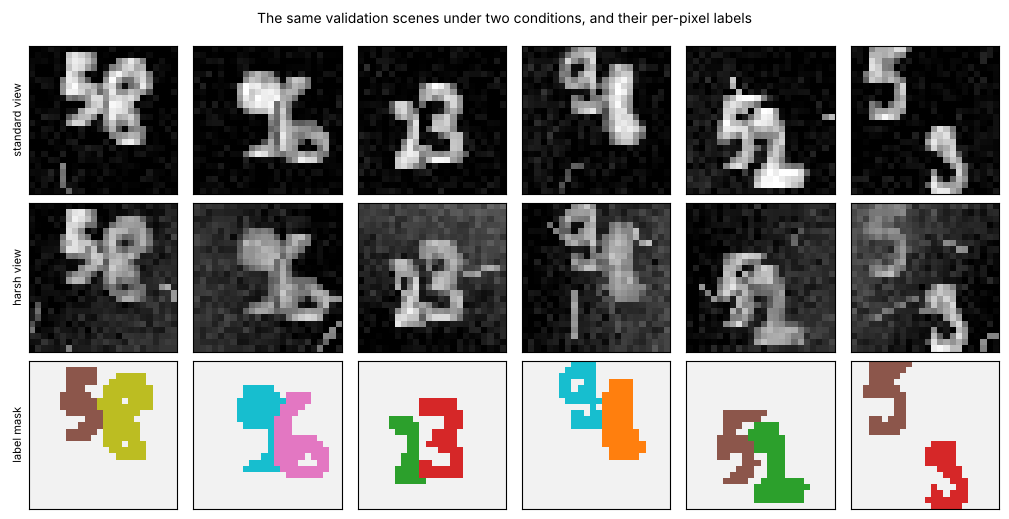

Mask colours: grey = background, then digits 0-9 in order: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9


In [3]:
DATA, open_test_once = prepare_data()
print('Scenes  train / validation / test:', N_TRAIN, N_VAL, N_TEST, '(test scenes are built only when opened)')
print('Image tensor:', tuple(DATA['val_harsh'].shape), '| mask tensor:', tuple(DATA['val_mask'].shape),
      DATA['val_mask'].dtype)
print(f"Normalisation from standard training images only: mean {DATA['mean']:.4f}, std {DATA['std']:.4f}")
show_masks([DATA['val_standard'], DATA['val_harsh'], DATA['val_mask']],
           ['standard view', 'harsh view', 'label mask'],
           suptitle='The same validation scenes under two conditions, and their per-pixel labels')
print('Mask colours: grey = background, then digits 0-9 in order:',
      ', '.join(f'{k}' for k in range(10)))

### Supplied engine and plotting helpers (identical to the assignment)

Run both cells now; section 7 explains how the engine works.

In [4]:
#@title Provided engine: metrics, prediction locks, training, log
def normalise(x):
    return (x - DATA['mean']) / DATA['std']

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def predict_logits(model, images, batch_size=400):
    model.eval()
    return torch.cat([model(normalise(images[i:i + batch_size]).to(DEVICE)).cpu()
                      for i in range(0, len(images), batch_size)])

def predict_masks(model, images, batch_size=400):
    return predict_logits(model, images, batch_size).argmax(1)

def segmentation_scores(pred, mask):
    """Engine metrics (computed with scikit-learn). mIoU averages classes present in prediction or truth."""
    cm = sk_confusion_matrix(mask.flatten().numpy(), pred.flatten().numpy(), labels=np.arange(NC))
    union = cm.sum(0) + cm.sum(1) - np.diag(cm)
    per_class = np.where(union > 0, np.diag(cm) / np.maximum(union, 1), np.nan)
    fg_pred, fg_true = pred > 0, mask > 0
    return dict(miou=float(np.nanmean(per_class)),
                fg_iou=float((fg_pred & fg_true).sum() / max((fg_pred | fg_true).sum(), 1)),
                digit_acc=float((pred[fg_true] == mask[fg_true]).float().mean()),
                pixel_acc=float((pred == mask).float().mean()),
                per_class_iou=per_class)

def predict(task, expected):
    """Record predictions before running a task's experiments. expected = {run_name: {metric: value}}.
    Re-running the cell with identical values is fine; changing them after runs exist is not."""
    if task not in TASKS:
        raise ValueError(f'task must be one of {TASKS}')
    if not expected or any(v is None for d in expected.values() for v in d.values()):
        raise ValueError('Fill in every predicted value (numbers, not None).')
    if task in PREDICTIONS and PREDICTIONS[task]['expected'] != expected:
        if any(r['task'] == task for r in RUNS.values()):
            raise RuntimeError(f'{task} runs already exist, so its predictions are frozen. '
                               'Discuss a revised expectation in writing instead.')
    PREDICTIONS[task] = dict(expected=copy.deepcopy(expected), time=time.strftime('%H:%M:%S'))
    print(f'{task}: predictions recorded at {PREDICTIONS[task]["time"]} for', ', '.join(expected))

def run_experiment(name, model_fn, task, aug=None, p_aug=0.5, seed=SEED, verbose=True):
    """Fresh model; fixed budget; final-epoch model; logs standard and harsh validation scores.
    aug: None, or a condition dict like STANDARD/HARSH used to re-render a fraction p_aug of each
    training batch (photometric only, so masks stay valid)."""
    if task not in TASKS:
        raise ValueError(f'task must be one of {TASKS}')
    if task not in PREDICTIONS and task not in ('guided', 'extension'):
        raise RuntimeError(f'Record your {task} predictions with predict(...) before running {task} experiments.')
    if TEST_OPENED and task != 'extension':
        raise RuntimeError('The test set is open. Only task="extension" runs are allowed now.')
    set_seed(seed)
    model = model_fn().to(DEVICE)
    signature = (str(model), repr(aug), p_aug, seed, task, EPOCHS, BATCH_SIZE, MAX_LR)
    if name in RUNS:
        if RUNS[name]['signature'] != signature:
            raise ValueError(f'"{name}" already records a different experiment. Use a new name; '
                             'the earlier run stays in the log.')
        if verbose:
            print(f'{name}: settings unchanged, reusing the recorded run.')
        return RUNS[name]
    optimizer = torch.optim.Adam(model.parameters(), lr=MAX_LR)
    steps = EPOCHS * math.ceil(N_TRAIN / BATCH_SIZE)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, total_steps=steps, pct_start=0.25)
    shuffle_gen = torch.Generator().manual_seed(seed + 1000)
    aug_gen = torch.Generator().manual_seed(seed + 2000)
    history, status, start = [], 'complete', time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(N_TRAIN, generator=shuffle_gen)
        total = 0.0
        for s in range(0, N_TRAIN, BATCH_SIZE):
            idx = order[s:s + BATCH_SIZE]
            x = DATA['train_img'][idx]
            if aug is not None:
                fresh = render(DATA['train_ink'][idx], aug_gen, aug)
                pick = torch.rand(len(idx), 1, 1, 1, generator=aug_gen) < p_aug
                x = torch.where(pick, fresh, x)
            loss = F.cross_entropy(model(normalise(x).to(DEVICE)), DATA['train_mask'][idx].to(DEVICE))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            schedule.step()
            total += loss.item() * len(idx)
        if not math.isfinite(total):
            status = 'failed'
            break
        history.append(dict(epoch=epoch, train_loss=total / N_TRAIN))
    run = dict(name=name, task=task, model=model.eval(), model_fn=model_fn.__name__, aug=aug, p_aug=p_aug,
               seed=seed, status=status, signature=signature, history=pd.DataFrame(history),
               parameters=count_parameters(model), seconds=time.perf_counter() - start)
    if status == 'complete':
        for view in ('standard', 'harsh'):
            scores = segmentation_scores(predict_masks(model, DATA['val_' + view]), DATA['val_mask'])
            run.update({f'{view}_{k}': v for k, v in scores.items()})
        run['train_loss'] = history[-1]['train_loss']
    RUNS[name] = run
    if verbose:
        print(f"{name:20s} {status} | params {run['parameters']:7,d} | {run['seconds']:5.1f} s | "
              f"standard mIoU {run.get('standard_miou', float('nan')):.3f} | "
              f"harsh mIoU {run.get('harsh_miou', float('nan')):.3f}")
    return run

LOG_COLUMNS = ['name', 'task', 'model_fn', 'parameters', 'seconds', 'train_loss',
               'standard_miou', 'standard_fg_iou', 'standard_digit_acc', 'standard_pixel_acc',
               'harsh_miou', 'harsh_fg_iou', 'harsh_digit_acc']

def experiment_table(tasks=None):
    rows = [{k: r.get(k) for k in LOG_COLUMNS} for r in RUNS.values() if tasks is None or r['task'] in tasks]
    return pd.DataFrame(rows, columns=LOG_COLUMNS)

def prediction_check(task):
    """Your recorded predictions next to the observed validation values."""
    rows = []
    for run_name, metrics in PREDICTIONS[task]['expected'].items():
        for metric, guess in metrics.items():
            observed = RUNS[run_name].get(metric) if run_name in RUNS else None
            rows.append(dict(run=run_name, metric=metric, predicted=guess, observed=observed,
                             error=None if observed is None else observed - guess))
    return pd.DataFrame(rows)

In [5]:
#@title Provided analysis and plotting helpers
def show_predictions(runs, view='harsh', n=6, start=0):
    images = DATA['val_' + view][start:start + n]
    rows, titles = [images, DATA['val_mask'][start:start + n]], [f'{view} image', 'true mask']
    for run in runs:
        rows.append(predict_masks(run['model'], images))
        titles.append(run['name'])
    show_masks(rows, titles, n=n, suptitle=f'Validation scenes ({view} view)')

def plot_losses(runs, title):
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for run in runs:
        h = run['history']
        if len(h):
            ax.plot(h.epoch, h.train_loss, marker='o', ms=3, label=run['name'])
    ax.set(xlabel='Epoch', ylabel='Training cross-entropy', yscale='log', title=title)
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

def per_class_table(runs, view='harsh'):
    names = ['background'] + [f'digit {k}' for k in range(10)]
    return pd.DataFrame({r['name']: r[f'{view}_per_class_iou'] for r in runs}, index=names)

def measure_receptive_field(layers, size=64, seed=0):
    """Empirical receptive field: input pixels whose gradient reaches the central output unit."""
    torch.manual_seed(seed)
    net = nn.Sequential(*layers).eval()
    x = torch.randn(4, 1, size, size, requires_grad=True)
    out = net(x)
    out[:, :, out.shape[-2] // 2, out.shape[-1] // 2].sum().backward()
    nz = torch.nonzero(x.grad.abs().sum((0, 1)))
    return int(nz[:, 0].max() - nz[:, 0].min() + 1)

def time_call(fn, repeats=3):
    best = float('inf')
    for _ in range(repeats):
        start = time.perf_counter()
        out = fn()
        best = min(best, time.perf_counter() - start)
    return out, best

**Check:** the harsh view has *the same labels* as the standard view. Which kind of model mistake would show up only in the harsh view?

## 2. Dense prediction: shapes and the per-pixel loss · minutes 4–8

A classifier returns `N × C` scores. A segmentation network returns **`N × C × H × W`**: a score for every class at every pixel (slide 68). `F.cross_entropy` accepts this directly with an integer target of shape `N × H × W`, and averages the loss over all pixels.

**Predict:** an untrained network outputs roughly equal scores for the 11 classes. What loss do you expect? *Answer: ln 11 ≈ 2.398.*

In [6]:
torch.manual_seed(0)
tiny = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, NC, 1))   # a 2-layer network
x, y = normalise(DATA['train_img'][:4]), DATA['train_mask'][:4]
logits = tiny(x)
print('input', tuple(x.shape), '-> logits', tuple(logits.shape), '| target', tuple(y.shape), y.dtype)
per_pixel = F.cross_entropy(logits, y, reduction='none')            # one loss value per pixel
print('per-pixel loss map', tuple(per_pixel.shape), '| mean', round(per_pixel.mean().item(), 3),
      '| ln 11 =', round(math.log(NC), 3))
frac = (DATA['train_mask'] == 0).float().mean().item()
print(f'Background pixels in training masks: {frac:.1%} of all pixels')

input (4, 1, 24, 24) -> logits (4, 11, 24, 24) | target (4, 24, 24) torch.int64
per-pixel loss map (4, 24, 24) | mean 2.737 | ln 11 = 2.398
Background pixels in training masks: 80.7% of all pixels


The untrained loss is close to ln 11, slightly higher because random initial scores are not exactly equal. Two consequences:

- The loss is an average over pixels, and about 80% of pixels are background. A network can lower the loss a lot just by learning "mostly background" before it learns anything about digits.
- `argmax` over the class dimension (`logits.argmax(1)`) gives an `N × H × W` predicted mask, which we compare pixel by pixel with the truth.

## 3. Measuring segmentation: pixel accuracy, IoU, Dice · minutes 8–12

For one class, with predicted pixel set *P* and true pixel set *T*:

$$\text{IoU} = \frac{|P \cap T|}{|P \cup T|}, \qquad \text{Dice} = \frac{2\,|P \cap T|}{|P| + |T|}.$$

**mIoU** averages IoU over classes. Below, one small object (class 1) sits on a large background (class 0). **Predict:** a prediction that misses the object completely; what are its pixel accuracy and the IoU of class 1?

In [7]:
truth = torch.zeros(10, 10, dtype=torch.long)
truth[3:6, 4:7] = 1                                  # a 3 x 3 object: 9 of 100 pixels
miss = torch.zeros_like(truth)                       # predicts background everywhere
shifted = torch.zeros_like(truth); shifted[4:7, 5:8] = 1   # right size, one pixel down and right

def iou_dice(pred, true, k):
    p, t = pred == k, true == k
    inter, union = (p & t).sum().item(), (p | t).sum().item()
    return inter / union if union else float('nan'), 2 * inter / (p.sum() + t.sum()).item()

for name, pred in [('misses the object', miss), ('object shifted by 1 px', shifted)]:
    iou0, _ = iou_dice(pred, truth, 0)
    iou1, dice1 = iou_dice(pred, truth, 1)
    print(f'{name:24s} pixel acc {(pred == truth).float().mean():.2f} | IoU bg {iou0:.2f} | '
          f'IoU object {iou1:.2f} | Dice object {dice1:.2f} | mIoU {(iou0 + iou1) / 2:.2f}')

misses the object        pixel acc 0.91 | IoU bg 0.91 | IoU object 0.00 | Dice object 0.00 | mIoU 0.46
object shifted by 1 px   pixel acc 0.90 | IoU bg 0.90 | IoU object 0.29 | Dice object 0.44 | mIoU 0.59


Missing the object entirely still gives **91% pixel accuracy**: the same trap as Lab 4's "always negative" rule. IoU of the object is 0, so mIoU halves. A one-pixel shift of a 3×3 object already drops its IoU to 0.29: **IoU is very sensitive to boundary errors on small or thin objects**. Dice is always at least as large as IoU (Dice = 2·IoU / (1 + IoU)).

A class that appears in *neither* the prediction nor the truth has an undefined IoU (0/0). In **T1** you will compute IoU for all 11 classes at once from a confusion matrix and decide how to treat such classes.

## 4. Sliding window, fully convolutional, down- and upsampling · minutes 12–17

**Sliding window (slide 67):** classify each pixel from a patch around it. **Predict:** how many patches does one 24×24 image need with a 15×15 window? `F.unfold` extracts them all at once.

In [8]:
padded = F.pad(DATA['val_standard'][:1], (7, 7, 7, 7))
patches = F.unfold(padded, 15)                                   # one column per output pixel
print('padded image', tuple(padded.shape), '-> patches', tuple(patches.shape),
      '=', patches.shape[-1], 'patches of', patches.shape[1], 'pixels')
neighbours = patches[0, :, 0].view(15, 15), patches[0, :, 1].view(15, 15)
print('Two horizontally neighbouring patches share', int((neighbours[0][:, 1:] == neighbours[1][:, :-1]).all()) * 14,
      'of their 15 columns')

padded image (1, 1, 38, 38) -> patches (1, 225, 576) = 576 patches of 225 pixels
Two horizontally neighbouring patches share 14 of their 15 columns


Neighbouring patches overlap almost completely, so a sliding window recomputes the same features again and again. A **convolution already slides**: applied to the whole image, each output pixel gets exactly what the layer would compute on the patch around it. We check this for one convolution layer.

In [9]:
torch.manual_seed(0)
conv = nn.Conv2d(1, 4, 3)                          # no padding, like inside a patch
image = torch.randn(1, 1, 12, 12)
whole = conv(image)                                # every position at once: 1 x 4 x 10 x 10
r, c = 5, 2
one_patch = conv(image[:, :, r:r + 3, c:c + 3])    # the 3x3 patch whose output lands at (r, c)
print('whole-image output at (r, c):', whole[0, :, r, c].detach().numpy().round(4))
print('patch output:                ', one_patch[0, :, 0, 0].detach().numpy().round(4))

whole-image output at (r, c): [-0.227   0.408   0.4917 -0.37  ]
patch output:                 [-0.227   0.408   0.4917 -0.37  ]


Identical. A network made only of convolutions is therefore a sliding window computed efficiently. In **T2** your teammate's patch classifier ends in an `nn.Linear` layer, and you will have to decide how that layer fits into this picture.

**Down- and upsampling (slide 69).** Pooling or strided convolution shrinks the map and widens the context; upsampling brings it back to full resolution. Follow the shapes:

In [10]:
x = torch.randn(1, 5, 16, 16)
down = F.max_pool2d(x, 2)
print('max-pool 2x2           ', tuple(x.shape), '->', tuple(down.shape))
print('bilinear upsample x2   ', tuple(down.shape), '->', tuple(F.interpolate(down, scale_factor=2, mode='bilinear', align_corners=False).shape))
print('transposed conv, s=2   ', tuple(down.shape), '->', tuple(nn.ConvTranspose2d(5, 5, 2, stride=2)(down).shape))
other = torch.randn(1, 3, 16, 16)
print('concatenate on channels', tuple(x.shape), '+', tuple(other.shape), '->', tuple(torch.cat([x, other], dim=1).shape))

max-pool 2x2            (1, 5, 16, 16) -> (1, 5, 8, 8)
bilinear upsample x2    (1, 5, 8, 8) -> (1, 5, 16, 16)
transposed conv, s=2    (1, 5, 8, 8) -> (1, 5, 16, 16)
concatenate on channels (1, 5, 16, 16) + (1, 3, 16, 16) -> (1, 8, 16, 16)


Concatenation needs the same height and width and adds the channel counts. That is how a **skip connection** in an encoder–decoder passes high-resolution encoder features to the decoder (slide 52: skip connections *add or concatenate*). In **T3** you will build the decoder and find out what the skips are for.

## 5. BatchNorm in training and evaluation; residual paths · minutes 17–22

BatchNorm (slides 48–50) normalises each channel with a mean and variance. **Which** mean and variance depends on the mode:

- `model.train()`: the statistics of the **current batch**, and the layer also updates its stored *running* statistics.
- `model.eval()`: the stored running statistics, so each image is processed on its own.

**Predict:** in training mode, does an image's output depend on which other images are in the batch?

In [11]:
torch.manual_seed(0)
bn = nn.BatchNorm2d(1)
a = torch.randn(1, 1, 4, 4)
batch_1 = torch.cat([a, torch.randn(3, 1, 4, 4)])           # a with three companions
batch_2 = torch.cat([a, 5 + torch.randn(3, 1, 4, 4)])       # a with very different companions
bn.train()
with torch.no_grad():
    out1, out2 = bn(batch_1)[0], bn(batch_2)[0]
print('train mode: same image, different companions -> max difference', round((out1 - out2).abs().max().item(), 3))
print('running mean after two "evaluation" passes in train mode:', round(bn.running_mean.item(), 3), '(started at 0)')
bn.eval()
with torch.no_grad():
    print('eval mode:  same image, different companions -> max difference',
          round((bn(batch_1)[0] - bn(batch_2)[0]).abs().max().item(), 3))

train mode: same image, different companions -> max difference 2.115
running mean after two "evaluation" passes in train mode: 0.379 (started at 0)
eval mode:  same image, different companions -> max difference 0.0


In training mode one image's output depends on its batch companions, and even a forward pass under `torch.no_grad()` changes the stored running mean. Evaluation must use `model.eval()`. In **T4a** you will diagnose what happens when that is forgotten.

**Residual paths (slides 51–52).** A residual block computes y = x + f(x). By the chain rule dy/dx = 1 + df/dx, so the gradient always has a direct path back. **Predict:** stack 30 small layers. Which gradient survives?

In [12]:
x0 = torch.tensor(1.0, requires_grad=True)
h = x0
for _ in range(30):
    h = torch.tanh(0.5 * h)                       # plain: each layer multiplies the gradient by < 0.5
h.backward()
print('plain stack of 30 layers:    dy/dx =', f'{x0.grad.item():.1e}')
x1 = torch.tensor(1.0, requires_grad=True)
h = x1
for _ in range(30):
    h = h + 0.05 * torch.tanh(0.5 * h)            # residual: identity path plus a small correction
h.backward()
print('residual stack of 30 layers: dy/dx =', f'{x1.grad.item():.2f}')

plain stack of 30 layers:    dy/dx = 6.8e-10
residual stack of 30 layers: dy/dx = 1.61


The plain stack's gradient has vanished (about 7e-10); the residual stack's stays of order 1 (about 1.6). In **T4b–c** you will implement the convolutional residual block of slide 52 and measure the same effect in real networks.

## 6. Augmentation for segmentation; a self-supervised pretext task · minutes 22–26

Augmentation transforms training data to create more varied examples (slides 56–61). For segmentation, the label map has to stay correct:

- **Geometric** changes (shifts, flips, crops) move pixels, so the **mask must move with the image**, using *the same random choice*.
- **Photometric** changes (brightness, lighting, noise) do not move pixels, so they apply to the **image only**; the mask stays as it is.

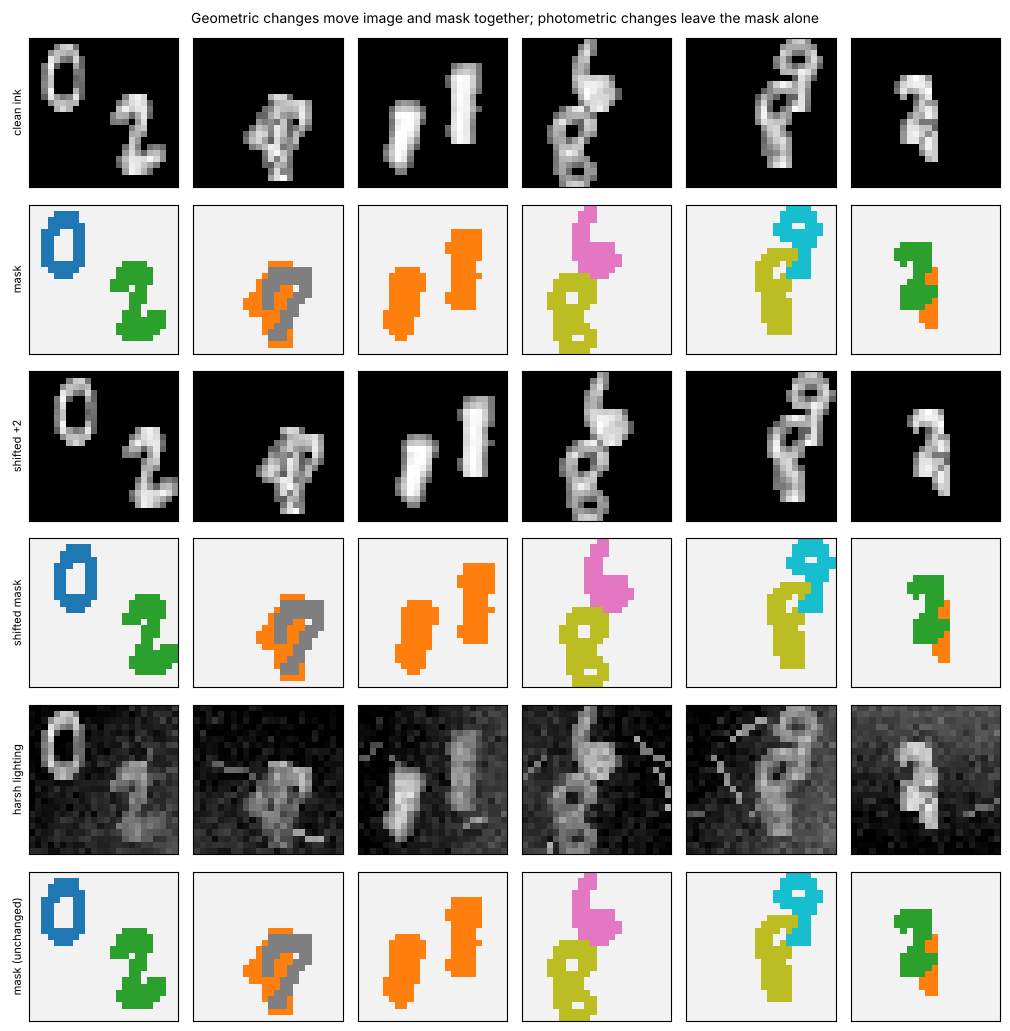

In [13]:
gen = torch.Generator().manual_seed(3)
ink, mask = DATA['train_ink'][:6], DATA['train_mask'][:6]
shift = int(torch.randint(-3, 4, (1,), generator=gen))                       # ONE random draw ...
shifted_img, shifted_mask = ink.roll(shift, dims=-1), mask.roll(shift, dims=-1)   # ... used for both
relit = render(ink, gen, HARSH)                                               # photometric: image only
show_masks([ink, mask, shifted_img, shifted_mask, relit, mask],
           ['clean ink', 'mask', f'shifted {shift:+d}', 'shifted mask', 'harsh lighting', 'mask (unchanged)'], n=6,
           suptitle='Geometric changes move image and mask together; photometric changes leave the mask alone')

Augmentation can also *change the meaning* of a label: in Lab 4 a mirrored 2 was no longer a 2. In **T5** you will audit an augmentation function written by an AI assistant and design checks that catch what goes wrong.

**Self-supervised learning (slides 43–46).** Labels are expensive: our masks needed one decision per pixel. A *pretext task* creates labels for free from unlabelled images, for example "by how much was this image rotated?". A network that solves the pretext task may learn features that help the real (*downstream*) task.

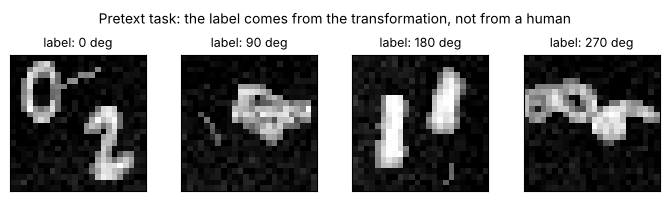

In [14]:
scenes = DATA['train_img'][:4]
rotations = torch.tensor([0, 1, 2, 3])
pretext_x = torch.stack([torch.rot90(img, int(k), dims=(-2, -1)) for img, k in zip(scenes, rotations)])
fig, axes = plt.subplots(1, 4, figsize=(7, 2))
for ax, img, k in zip(axes, pretext_x, rotations):
    ax.imshow(img[0], cmap='gray', vmin=0, vmax=1); ax.set_title(f'label: {90 * int(k)} deg', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Pretext task: the label comes from the transformation, not from a human', fontsize=10)
fig.tight_layout(); plt.show()

**Discuss:** is "how much was it rotated?" always answerable for a scene of digits? (Think of 0, 1, 8, and 6 versus 9.) A pretext task only helps if solving it requires features the downstream task needs. An optional deeper investigation in the assignment tests this one.

## 7. The experiment engine and a first baseline · minutes 26–30

`run_experiment(name, model_fn, task, aug=None)` trains a fresh model under a fixed budget: 12 epochs, batch 32, Adam with a one-cycle schedule, seed 42. It then scores both validation views with **mIoU**, **foreground IoU** (ink vs background, ignoring which digit), **digit accuracy** (on true digit pixels, the share labelled with the right digit) and **pixel accuracy**.

Before a task's runs, the engine requires your **predictions** via `predict(...)`; `prediction_check(...)` later compares them with the results. We try it with a deliberately small network: two 3×3 convolutions, so each output pixel sees only 5×5 input pixels.

**Predict:** will this tiny network find *where* the ink is, *which* digit it is, both, or neither?

guided: predictions recorded at 10:12:35 for Guided_tiny_fcn


Guided_tiny_fcn      complete | params     763 |   2.1 s | standard mIoU 0.100 | harsh mIoU 0.089


,run,metric,predicted,observed,error
0,Guided_tiny_fcn,standard_fg_iou,0.8,0.932,0.132
1,Guided_tiny_fcn,standard_digit_acc,0.2,0.094,-0.106


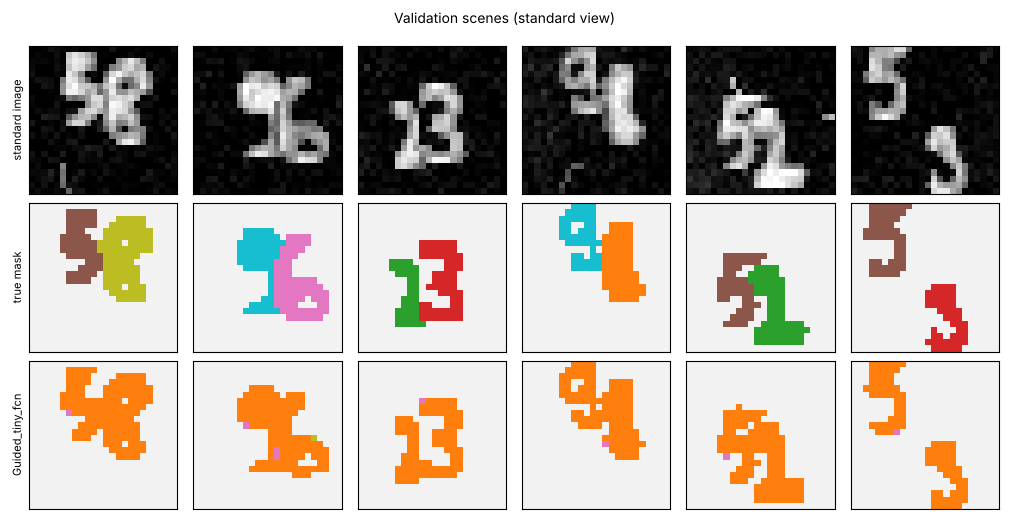

In [15]:
def tiny_fcn():
    return nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.Conv2d(8, 8, 3, padding=1), nn.ReLU(),
                         nn.Conv2d(8, NC, 1))

predict('guided', {'Guided_tiny_fcn': dict(standard_fg_iou=0.8, standard_digit_acc=0.2)})   # the class's guess
guided = run_experiment('Guided_tiny_fcn', tiny_fcn, 'guided')
display(prediction_check('guided').round(3))
show_predictions([guided], view='standard')

With a 5-pixel view, the network finds the strokes (*where*: foreground IoU above 0.9) but cannot see enough of a digit to know *which* digit it is (*what*). It labels almost every stroke with one class, so its digit accuracy is near chance (one in ten).

## The assignment challenge

A camera must segment digits on forms lit from one side. In the assignment you will:

1. **T1** compute IoU for 11 classes from a confusion matrix, and see what mIoU rewards;
2. **T2** turn a sliding-window patch classifier into a fully convolutional network with identical scores;
3. **T3** build a small U-Net and find out what skip connections add (*where* vs *what*);
4. **T4** debug a BatchNorm evaluation, implement a residual block, and train deep networks;
5. **T5** audit an AI-written augmentation, test a claim about the harsh images, freeze your decision, and open the test set once.

Predictions come before runs, and plans before code. We stop here without evaluating any test data. Start the assignment now.

## References and credits

- BME lecture: *Deep Learning — Computer Vision* (27 October 2026), supplied course slides.
- [scikit-learn: the 8×8 digits dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), derived from the UCI Optical Recognition of Handwritten Digits data (E. Alpaydin, C. Kaynak). This is **not MNIST**. The scenes, lighting and clutter are artificial classroom transformations.
- Long, Shelhamer & Darrell (2015), [Fully Convolutional Networks for Semantic Segmentation](https://arxiv.org/abs/1411.4038); Ronneberger, Fischer & Brox (2015), [U-Net](https://arxiv.org/abs/1505.04597).
- Ioffe & Szegedy (2015), [Batch Normalization](https://arxiv.org/abs/1502.03167); He et al. (2016), [Deep Residual Learning](https://arxiv.org/abs/1512.03385); Gidaris et al. (2018), [Predicting Image Rotations](https://arxiv.org/abs/1803.07728).

Course material: Dr. Mohammed Salah Al-Radhi, BME. Dataset and framework credits remain with their authors.